# Tutorial 5: Spatial early warning signals with *ewstools*

By the end of this tutorial you should know how to:
- Build a spatial weights matrix for a regular grid with `lattice_weights`
- Compute Moran's I, and its permutation p-value, at every time point with `SpatialEWS`
- Measure the trend of Moran's I with Kendall tau
- Tell a rising Moran's I that comes from critical slowing down apart from one that comes from a strengthening spatial pattern, using the trend-control recipe

Total run time : about 25 s on a Windows PC (Python 3.12)

## Motivation

Most early warning signals (EWS) in *ewstools* are temporal: a rolling window slides along one time series and an indicator such as variance or lag-1 autocorrelation is tracked over time. When a system is observed at many places at once (a grid of cells, a network of sensors, a set of regions), there is a second signal to look at, across **space**. As a system approaches a critical transition its relaxation slows down, so a perturbation at one unit is felt for longer by its neighbours, and neighbouring units become more similar to each other. This is the spatial branch of critical slowing down ([Dakos et al. (2010) Theor. Ecol.](https://link.springer.com/article/10.1007/s12080-009-0060-6)).

The standard statistic for it is Moran's I, a measure of spatial autocorrelation: it is positive when neighbouring units tend to have similar values and negative when they tend to differ. `ewstools.spatial` computes it **cross-sectionally**, one value per time point, from a `DataFrame` with one column per spatial unit and one row per time point. The trend of that series is then measured with Kendall tau, as for the temporal indicators.

A rising Moran's I is not specific to critical slowing down, which is why the second half of this tutorial is about **trend control**.

## Import libraries

In [1]:
# Start timer to record execution time of notebook
import time
start_time = time.time()

In [2]:
import warnings

import numpy as np
np.random.seed(0)  # Set seed for reproducibility
import pandas as pd
import matplotlib.pyplot as plt

import ewstools
from ewstools import MultiTimeSeries
from ewstools.spatial import SpatialEWS, lattice_weights, morans_i

# MultiTimeSeries.detrend adds two columns per variable one at a time. With one
# column per spatial unit, pandas warns about a fragmented DataFrame. Harmless.
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

## Simulate a spatial system approaching a transition

We use a $10 \times 10$ grid of units. Each unit $x_i$ has two stable states, and diffuses towards its four nearest neighbours:

$$
\mathrm{d}x_i = \Big[\, x_i - x_i^3 + h(t) + D \sum_{j \sim i} (x_j - x_i) \Big]\mathrm{d}t + \sigma \, \mathrm{d}W_i
$$

where $h(t)$ is a slowly decreasing control parameter and $\mathrm{d}W_i$ is independent noise on each unit. All units start on the upper branch ($x \approx 1$). When $h$ reaches $-2/(3\sqrt{3}) \approx -0.385$ that branch disappears in a fold bifurcation, and the system collapses to the lower branch. The relaxation rate of the upper branch goes to zero at the fold, so this is a critical transition with critical slowing down.

The function below simulates the field with the Euler-Maruyama method and records one row per unit of time. It stops the first time the spatial mean crosses 0 (the unstable middle branch), and returns that time as the transition.

In [3]:
GRID = 10  # grid is GRID x GRID units
FOLD = -2 / (3 * np.sqrt(3))  # value of h at the fold bifurcation


def simulate_field(seed, sigma=0.2, h_start=-0.2, h_end=FOLD, D=1.0,
                   t_max=300, dt=0.1, burn_in=50):
    """Grid of coupled bistable units. h(t) goes linearly from h_start to h_end.
    Returns the field as a DataFrame (rows: time, columns: units) and the time
    at which the spatial mean crosses 0, or None if that never happens."""
    rng = np.random.default_rng(seed)
    W = lattice_weights(GRID)       # rook neighbours
    degree = W.sum(axis=1)
    n_units = GRID * GRID

    def step(x, h):
        coupling = D * (W @ x - degree * x)
        return x + dt * (x - x**3 + h + coupling) + sigma * np.sqrt(dt) * rng.normal(size=n_units)

    x = np.ones(n_units)
    for _ in range(int(burn_in / dt)):   # settle near the equilibrium at h_start
        x = step(x, h_start)

    rows, times, t_transition = [], [], None
    for k in range(int(t_max / dt)):
        t = k * dt
        x = step(x, h_start + (h_end - h_start) * t / t_max)
        if k % int(1 / dt) == 0:         # record once per unit of time
            rows.append(x.copy())
            times.append(t)
            if x.mean() < 0:
                t_transition = t
                break
    return pd.DataFrame(rows, index=pd.Index(times, name="time")), t_transition


df, t_transition = simulate_field(seed=1)
print(f"{df.shape[0]} time points, {df.shape[1]} units. Transition at t = {t_transition}")
df.iloc[:3, :6]

276 time points, 100 units. Transition at t = 275.0


,0,1,2,3,4,5
time,,,,,,
0.0,0.836740,0.836694,0.924558,0.834799,0.909147,0.719392
1.0,0.822019,0.750400,0.844481,0.978201,0.905084,0.909832
2.0,0.826272,0.866142,0.767011,0.773973,0.865191,0.789750


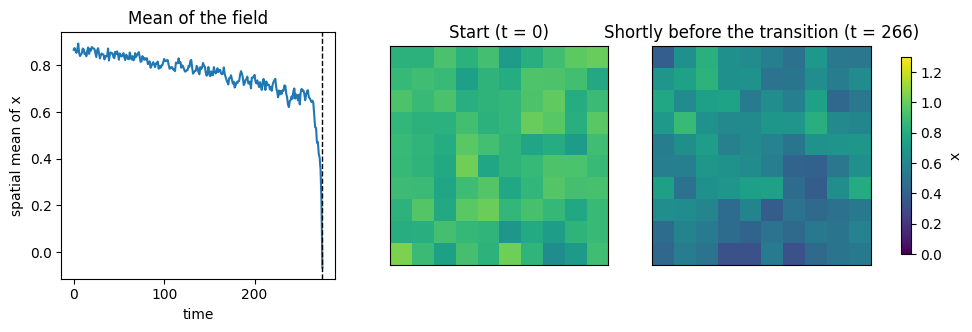

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))

axes[0].plot(df.index, df.mean(axis=1))
axes[0].axvline(t_transition, color="k", ls="--", lw=1)
axes[0].set(xlabel="time", ylabel="spatial mean of x", title="Mean of the field")

for ax, t, title in [(axes[1], df.index[0], "Start"), (axes[2], df.index[-10], "Shortly before the transition")]:
    im = ax.imshow(df.loc[t].to_numpy().reshape(GRID, GRID), vmin=0, vmax=1.3, cmap="viridis")
    ax.set(title=f"{title} (t = {t:.0f})", xticks=[], yticks=[])
fig.colorbar(im, ax=axes[1:], shrink=0.8, label="x")
plt.show()

The difference between the two snapshots is hard to judge by eye: both are noisy, and close to the transition the field is only slightly more patchy. Moran's I puts a number on it.

## Compute Moran's I and its significance

A `SpatialEWS` object takes the data and a **spatial weights matrix** `weights`, with `weights[i, j] > 0` if units `i` and `j` are neighbours. `lattice_weights` builds one for a regular grid (rook connectivity by default; `connectivity="queen"` adds the diagonal neighbours). Cell `(row, col)` of the grid is unit number `row * n_cols + col`, which is the order of `.flatten()`. For irregular networks, build `weights` with a library such as [libpysal](https://pysal.org/libpysal/) and pass the dense array.

`weights` is matched to the columns of `data` **by position**, so do not reorder the columns after building it. It must be finite and have a zero diagonal, and an error is raised otherwise: self-weights would inflate Moran's I.

Passing `transition` restricts the computation to the time points up to the transition.

In [5]:
weights = lattice_weights(GRID)
print(weights.shape, "| neighbours of unit 0 (corner):", int(weights[0].sum()), "| of unit 11 (inside):", int(weights[11].sum()))

spatial = SpatialEWS(df, weights, transition=t_transition)
spatial.compute_moran()
spatial.compute_moran_significance(n_permutations=200, seed=1)
spatial.ews.head()

(100, 100) | neighbours of unit 0 (corner): 2 | of unit 11 (inside): 4


,morans_i,morans_i_pvalue
time,,
0.0,0.106552,0.079602
1.0,0.082215,0.119403
2.0,0.243796,0.004975
3.0,0.050618,0.233831
4.0,0.161003,0.024876


`compute_moran_significance` reshuffles the values across units 200 times at each time point, keeping the network fixed, and stores in `morans_i_pvalue` the fraction of reshuffles with a Moran's I at least as large as the observed one. It is one-sided, because an *increase* in spatial correlation is the warning sign. The p-value cannot be smaller than $1/(n_{\mathrm{permutations}}+1)$. Each time point gets its own permutations, and results are reproducible for a given `seed`.

Kendall tau against time: {'morans_i': 0.255, 'morans_i_pvalue': -0.24}
Share of time points with p < 0.05: 84%


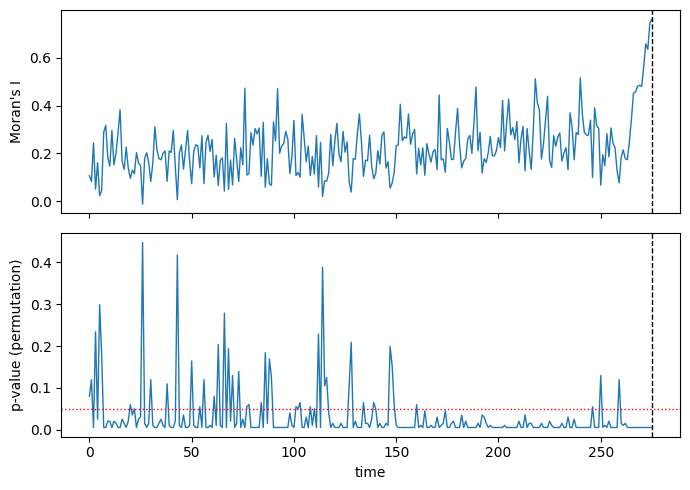

In [6]:
spatial.compute_ktau()
print("Kendall tau against time:", {k: round(v, 3) for k, v in spatial.ktau.items()})
print(f"Share of time points with p < 0.05: {(spatial.ews['morans_i_pvalue'] < 0.05).mean():.0%}")

fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
axes[0].plot(spatial.ews["morans_i"], lw=1)
axes[0].set(ylabel="Moran's I")
axes[1].plot(spatial.ews["morans_i_pvalue"], lw=1)
axes[1].axhline(0.05, color="r", ls=":", lw=1)
axes[1].set(ylabel="p-value (permutation)", xlabel="time")
for ax in axes:
    ax.axvline(t_transition, color="k", ls="--", lw=1)
plt.tight_layout()
plt.show()

`compute_ktau` returns one tau per computed column: the first is the trend of Moran's I, the second the trend of its p-value (negative, because the p-values tend to fall).

Moran's I fluctuates around a low level for most of the record and rises steeply over the last stretch before the transition. Each point comes from a single snapshot of 100 units, so the series is noisy, and Kendall tau over the whole record is moderate even though the final rise is large.

Note that the p-values are below 0.05 at most time points, from the start of the record. The units are coupled, so neighbours are correlated all along: a significant Moran's I at one time point says that spatial correlation is present, not that a transition is near. What carries the warning is the **trend**.

## Is a positive trend meaningful? A control without approach

Kendall tau is not zero by construction, so it is worth checking what it looks like when nothing is happening. As a control we run the same model with the control parameter held fixed at its starting value, so that the system does not approach the fold. We repeat both the approach and the control over several random seeds.

In [7]:
n_seeds = 10
tau_approach, tau_control = [], []
for seed in range(n_seeds):
    df_a, t_a = simulate_field(seed=100 + seed)
    s = SpatialEWS(df_a, weights, transition=t_a)
    s.compute_moran(); s.compute_ktau()
    tau_approach.append(s.ktau["morans_i"])

    df_c, _ = simulate_field(seed=200 + seed, h_end=-0.2, t_max=200)   # h stays at its start value
    s = SpatialEWS(df_c, weights)
    s.compute_moran(); s.compute_ktau()
    tau_control.append(s.ktau["morans_i"])

print(f"Approaching the fold : tau = {np.mean(tau_approach):+.2f}  (range {min(tau_approach):+.2f} to {max(tau_approach):+.2f})")
print(f"Parameter held fixed : tau = {np.mean(tau_control):+.2f}  (range {min(tau_control):+.2f} to {max(tau_control):+.2f})")

Approaching the fold : tau = +0.34  (range +0.26 to +0.39)
Parameter held fixed : tau = +0.02  (range -0.09 to +0.10)


With the parameter held fixed, tau scatters around zero. When the system approaches the fold it is consistently positive over the seeds. That is a real, but modest, signal: Moran's I computed from single snapshots is noisy, and the interpretation of a trend should not rest on one realisation.

## Trend control

Moran's I is computed on the raw field at each time point. It is centred on the spatial mean at each time, so a uniform drift of the whole field does nothing to it. But **a spatial pattern whose amplitude changes slowly in time** does change it, with no change in the dynamics of the system: Moran's I rises while a gradient strengthens, whether or not the system is slowing down.

To see this, here is a field with no critical slowing down at all: a west-to-east gradient whose strength grows over time, plus independent noise on each unit.

In [8]:
def strengthening_gradient(seed, n_time=300, noise=0.05):
    """No dynamics: a column gradient whose amplitude grows linearly, plus noise."""
    rng = np.random.default_rng(seed)
    column = np.indices((GRID, GRID))[1].flatten().astype(float)
    rows = [0.5 * column * (t / n_time) + rng.normal(scale=noise, size=GRID * GRID) for t in range(n_time)]
    return pd.DataFrame(rows, index=pd.Index(np.arange(n_time, dtype=float), name="time"))


df_grad = strengthening_gradient(seed=0)

spatial_raw = SpatialEWS(df_grad, weights)
spatial_raw.compute_moran(); spatial_raw.compute_ktau()
print("Kendall tau of Moran's I, raw field:", round(spatial_raw.ktau["morans_i"], 3))

Kendall tau of Moran's I, raw field: 0.711


Tau is large and positive, with nothing to warn about. A pipeline that only looked at the sign of tau would raise an alarm here.

The package already has the operation that removes this kind of pattern: `MultiTimeSeries.detrend` smooths each unit's series over time and returns the residuals. The recipe is to detrend first, then give the **residuals** to `SpatialEWS`. `MultiTimeSeries` appends columns to the DataFrame it is given, so pass a copy.

Kendall tau of Moran's I, raw field      : 0.711
Kendall tau of Moran's I, detrended field: -0.028


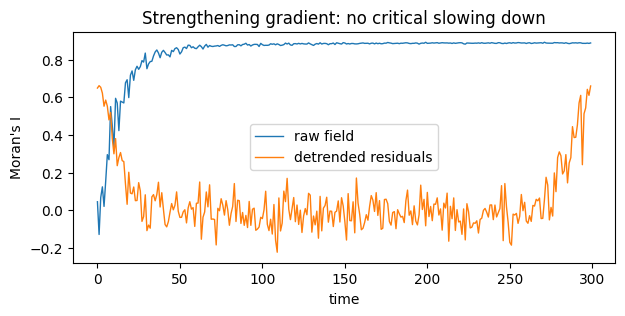

In [9]:
def detrended_spatial_ews(data, weights, transition=None, bandwidth=0.2):
    """Per-unit Gaussian detrend with MultiTimeSeries, then SpatialEWS on the residuals."""
    mts = MultiTimeSeries(data.copy(), transition=transition)
    mts.detrend(method="Gaussian", bandwidth=bandwidth)
    residuals = mts.state[[f"{c}_residuals" for c in data.columns]].set_axis(data.columns, axis=1)
    sews = SpatialEWS(residuals, weights=weights, transition=transition)
    sews.compute_moran()
    sews.compute_ktau()
    return sews


spatial_resid = detrended_spatial_ews(df_grad, weights)
print("Kendall tau of Moran's I, raw field      :", round(spatial_raw.ktau["morans_i"], 3))
print("Kendall tau of Moran's I, detrended field:", round(spatial_resid.ktau["morans_i"], 3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(spatial_raw.ews["morans_i"], label="raw field", lw=1)
ax.plot(spatial_resid.ews["morans_i"], label="detrended residuals", lw=1)
ax.set(xlabel="time", ylabel="Moran's I", title="Strengthening gradient: no critical slowing down")
ax.legend()
plt.show()

After detrending, the spurious trend is gone: over most of the record Moran's I of the residuals is close to zero. Look at the ends of the plot, though. The smoother reflects at both ends of the record, so part of the gradient survives in the first and last few rows and the residual series is U-shaped. Tau over the whole record is near zero partly because the two ends cancel out. When you apply the recipe, look at the residual series and not only at tau.

The same recipe applied to the field that **does** approach a transition gives a similar tau. That is expected here: every unit drifts in the same way as $h$ decreases, and a uniform drift does not change Moran's I, so there is no slowly varying spatial pattern to remove.

Approaching the fold, raw field      : 0.255
Approaching the fold, detrended field: 0.279


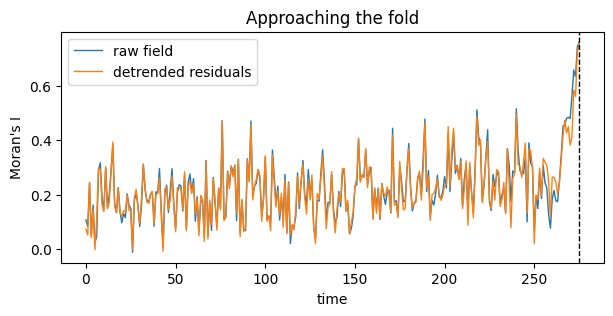

In [10]:
spatial_main = detrended_spatial_ews(df, weights, transition=t_transition)
print("Approaching the fold, raw field      :", round(spatial.ktau["morans_i"], 3))
print("Approaching the fold, detrended field:", round(spatial_main.ktau["morans_i"], 3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(spatial.ews["morans_i"], label="raw field", lw=1)
ax.plot(spatial_main.ews["morans_i"], label="detrended residuals", lw=1)
ax.axvline(t_transition, color="k", ls="--", lw=1)
ax.set(xlabel="time", ylabel="Moran's I", title="Approaching the fold")
ax.legend()
plt.show()

### What detrending does not do

- It removes **slowly varying patterns** only. A rise in the amplitude of spatially coherent fluctuations relative to unit-level noise also raises Moran's I, and a per-unit temporal smoother cannot touch it.
- Dakos et al. (2010, Fig. 6) show two further ways in which spatial correlation can rise with no change in proximity to a transition: increased connectivity between units and increased environmental heterogeneity.
- `weights` is fixed for the whole record. If the real network changes over time (units added or removed, links strengthened), Moran's I trends for that reason alone. Use a sub-network that is present and connected throughout.
- Moran's I depends on the units and the weights as much as on the field, so compare a candidate window against a reference period rather than reading an absolute level.
- A rising spatial correlation can also mark a system that is *evading* a transition through spatial self-organisation ([Rietkerk et al. (2021) Science](https://www.science.org/doi/10.1126/science.abj0359)). Treat a rising Moran's I as a prompt to ask why a pattern forms, not as a result.
- Time points with a missing unit, or with no variation across the field, give `nan` and a warning: missing units are not dropped, the whole time point is discarded.

`SpatialEWS` gives the trend of Moran's I over time. For an analytic significance test on a *single* snapshot, see `esda.moran.Moran` in [PySAL](https://pysal.org/esda/).

## Summary

In [11]:
print(f"Total run time of the notebook: {time.time() - start_time:.1f} s")

Total run time of the notebook: 21.8 s
